# ECHO — The Signal That Was Never Sent
## Entangled Minds: The Quantathon

**Participant:** Muhammad Feras Malik  
**GitHub:** Supl3x  
**Institution:** NED University of Engineering & Technology  
**Mandatory Modules:** 01, 03, 05  
**Selected Stretch Module:** 04 — The Erased Measurement

Run this notebook from top to bottom. For every module, the notebook includes the objective, prediction, code/circuit, result, interpretation, and a one-line **What this proves** statement.

# Setup
Run this cell first.

In [1]:
!pip install qiskit qiskit-aer pylatexenc matplotlib numpy --quiet

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

simulator = AerSimulator()

def run_circuit(circuit, shots=2000):
    compiled = transpile(circuit, simulator)
    result = simulator.run(compiled, shots=shots).result()
    return result.get_counts()

print("ECHO investigation environment ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.9 MB/s eta 0:00:00
ECHO investigation environment ready.


# Module 01 — The Gatekeeper

## Objective
- **Bronze:** produce a deterministic `1` and an approximately 50/50 bit.
- **Silver:** use a two-gate sequence that looks uncertain in the middle but finishes certain.
- **Gold:** create measured pattern `101` from `000`.

## Bronze A — Always 1
**Prediction:** `X|0⟩ = |1⟩`, so every ideal measurement should be `1`.

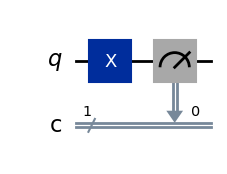

Counts: {'1': 1000}


In [2]:
qc_m1_one = QuantumCircuit(1, 1)
qc_m1_one.x(0)
qc_m1_one.measure(0, 0)

display(qc_m1_one.draw("mpl"))
counts_m1_one = run_circuit(qc_m1_one, shots=1000)
print("Counts:", counts_m1_one)
plot_histogram(counts_m1_one)
plt.show()

## Bronze B — 50/50 uncertainty
**Prediction:** `H|0⟩` creates a superposition, so repeated measurements should be approximately 50% `0` and 50% `1`.

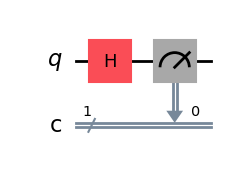

Counts: {'0': 1020, '1': 980}
P(0) = 0.51
P(1) = 0.49


In [3]:
qc_m1_random = QuantumCircuit(1, 1)
qc_m1_random.h(0)
qc_m1_random.measure(0, 0)

display(qc_m1_random.draw("mpl"))
counts_m1_random = run_circuit(qc_m1_random, shots=2000)
print("Counts:", counts_m1_random)

total = sum(counts_m1_random.values())
p0 = counts_m1_random.get("0", 0) / total
p1 = counts_m1_random.get("1", 0) / total
print("P(0) =", round(p0, 4))
print("P(1) =", round(p1, 4))

plot_histogram(counts_m1_random)
plt.show()

## Silver — H followed by H
**Prediction:** `H² = I`, so starting from `|0⟩`, the final result should always be `0`.

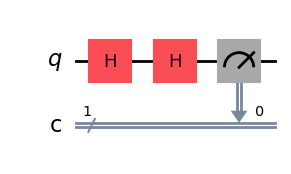

Counts: {'0': 1000}


In [4]:
qc_m1_silver = QuantumCircuit(1, 1)
qc_m1_silver.h(0)
qc_m1_silver.h(0)
qc_m1_silver.measure(0, 0)

display(qc_m1_silver.draw("mpl"))
counts_m1_silver = run_circuit(qc_m1_silver, shots=1000)
print("Counts:", counts_m1_silver)
plot_histogram(counts_m1_silver)
plt.show()

## Gold — Vault pattern 101
**Prediction:** starting from `|000⟩`, applying `X` to qubits 0 and 2 prepares `101`.

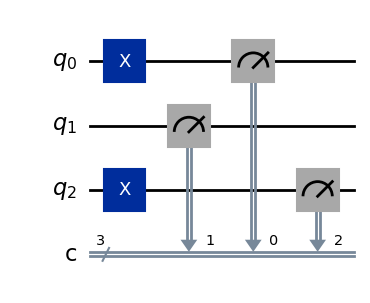

Counts: {'101': 1000}


In [5]:
qc_m1_gold = QuantumCircuit(3, 3)
qc_m1_gold.x(0)
qc_m1_gold.x(2)
qc_m1_gold.measure([0, 1, 2], [0, 1, 2])

display(qc_m1_gold.draw("mpl"))
counts_m1_gold = run_circuit(qc_m1_gold, shots=1000)
print("Counts:", counts_m1_gold)
plot_histogram(counts_m1_gold)
plt.show()

### Module 01 Interpretation
- `X` produced a deterministic `1`.
- `H` produced an approximately 50/50 result.
- `H → H` returned to the starting state.
- `101` was prepared successfully.

**What this proves:** The machine can reliably prepare deterministic states, superposition states, and the required 3-bit pattern using the allowed gates.

# Module 03 — The Two Observers

## Objective
- **Bronze:** build a Bell pair producing only `00` and `11` ideally.
- **Silver:** show a simple pre-agreed classical shared bit can imitate that same-basis agreement.
- **Gold:** change the measurement basis to distinguish the Bell pair from that specific simple classical model.

## Bronze — Bell pair
**Prediction:** `H` on qubit 0 followed by `CNOT(0→1)` creates `( |00⟩ + |11⟩ ) / √2`. In the computational basis, results should be about 50% `00` and 50% `11`.

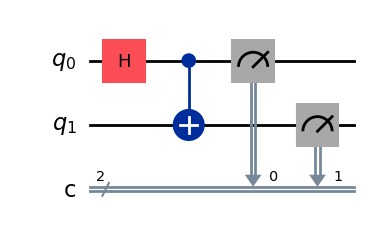

Bell pair Z-basis counts: {'11': 2004, '00': 1996}
Agreement percentage: 100.0 %
Mismatch percentage: 0.0 %


In [6]:
bell_z = QuantumCircuit(2, 2)
bell_z.h(0)
bell_z.cx(0, 1)
bell_z.measure([0, 1], [0, 1])

display(bell_z.draw("mpl"))
bell_z_counts = run_circuit(bell_z, shots=4000)
print("Bell pair Z-basis counts:", bell_z_counts)

total = sum(bell_z_counts.values())
agree = bell_z_counts.get("00", 0) + bell_z_counts.get("11", 0)
different = bell_z_counts.get("01", 0) + bell_z_counts.get("10", 0)
print("Agreement percentage:", round(100 * agree / total, 2), "%")
print("Mismatch percentage:", round(100 * different / total, 2), "%")

plot_histogram(bell_z_counts)
plt.show()

## Silver — Classical pre-agreement
**Prediction:** if two classical observers agree beforehand to output the same random bit, they also produce only `00` and `11`. Therefore same-basis agreement alone is not enough to prove entanglement.

In [7]:
shots = 4000
rng = np.random.default_rng()
classical_results = Counter()

for _ in range(shots):
    shared_bit = int(rng.integers(0, 2))
    classical_results["00" if shared_bit == 0 else "11"] += 1

classical_results = dict(classical_results)
print("Classical shared-bit counts:", classical_results)
plot_histogram(classical_results)
plt.show()

Classical shared-bit counts: {'00': 1997, '11': 2003}


## Gold — Change the measurement basis

For the Bell pair, apply `H` to both qubits immediately before computational-basis measurement. This is equivalent to measuring in the X basis.

**Prediction:** the Bell pair should still show same-result correlation.

For the simple classical model, prepare either `|00⟩` or `|11⟩`, then apply `H` to both before measurement.

**Prediction:** the classical mixture should produce approximately all four outcomes equally, so same-result agreement drops to about 50%.

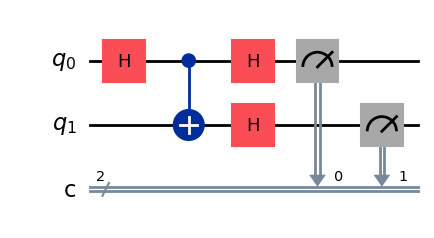

Bell pair X-basis counts: {'00': 1940, '11': 2060}


In [8]:
# Bell pair measured in X basis
bell_x = QuantumCircuit(2, 2)
bell_x.h(0)
bell_x.cx(0, 1)
bell_x.h(0)
bell_x.h(1)
bell_x.measure([0, 1], [0, 1])

display(bell_x.draw("mpl"))
bell_x_counts = run_circuit(bell_x, shots=4000)
print("Bell pair X-basis counts:", bell_x_counts)
plot_histogram(bell_x_counts)
plt.show()

In [9]:
# Classical mixture: half |00>, half |11>, then measure in X basis

def run_classical_x_case(bit_value, shots=2000):
    qc = QuantumCircuit(2, 2)
    if bit_value == 1:
        qc.x(0)
        qc.x(1)
    qc.h(0)
    qc.h(1)
    qc.measure([0, 1], [0, 1])
    return run_circuit(qc, shots=shots)

counts_00_x = run_classical_x_case(0, shots=2000)
counts_11_x = run_classical_x_case(1, shots=2000)

classical_x_total = Counter()
for k, v in counts_00_x.items():
    classical_x_total[k] += v // 2
for k, v in counts_11_x.items():
    classical_x_total[k] += v // 2
classical_x_total = dict(classical_x_total)

print("Classical mixture X-basis counts:", classical_x_total)
plot_histogram(classical_x_total)
plt.show()

Classical mixture X-basis counts: {'11': 492, '01': 519, '00': 501, '10': 487}


In [10]:
def agreement_rate(counts):
    total = sum(counts.values())
    same = counts.get("00", 0) + counts.get("11", 0)
    return same / total

quantum_x_agreement = agreement_rate(bell_x_counts)
classical_x_agreement = agreement_rate(classical_x_total)

print("Quantum X-basis agreement:", round(100 * quantum_x_agreement, 2), "%")
print("Classical X-basis agreement:", round(100 * classical_x_agreement, 2), "%")

Quantum X-basis agreement: 100.0 %
Classical X-basis agreement: 49.67 %


### Module 03 Interpretation
In one basis, both the Bell pair and the simple pre-agreed classical model can produce only `00` and `11`. Changing basis separates them: the Bell pair preserves same-result correlation, while the simple classical `00/11` mixture does not.

**Scientific limitation:** This distinguishes the Bell state from the specific pre-agreed shared-bit model used here. It is not presented as a proof against every possible classical hidden-variable model.

**What this proves:** Same-basis detector agreement alone cannot distinguish an entangled Bell pair from a simple pre-agreed classical correlation.

# Module 05 — The Damaged Message

## Objective
Recover the original message from the provided 3-bit repetition code.

In [11]:
corrupted_stream = """
100 011 001 001 001 011 100 110
001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000
000 111 001 010 101 011 111 111
"""

triples = corrupted_stream.split()
print("Number of triples:", len(triples))
print("Total bits:", len(triples) * 3)

Number of triples: 32
Total bits: 96


## Bronze — Majority decode
**Prediction:** if at most one bit in a triple is flipped, majority vote should recover the original bit.

In [12]:
def majority_vote(triple):
    return "1" if triple.count("1") > triple.count("0") else "0"

decoded_bits = ""
for triple in triples:
    bit = majority_vote(triple)
    decoded_bits += bit
    print(triple, "->", bit)

print("\nRecovered 32-bit binary:")
print(decoded_bits)

byte_groups = [decoded_bits[i:i+8] for i in range(0, len(decoded_bits), 8)]
print("\n8-bit groups:", byte_groups)

decoded_message = "".join(chr(int(byte, 2)) for byte in byte_groups)
print("\nRecovered ASCII message:")
print(decoded_message)

100 -> 0
011 -> 1
001 -> 0
001 -> 0
001 -> 0
011 -> 1
100 -> 0
110 -> 1
001 -> 0
011 -> 1
000 -> 0
000 -> 0
001 -> 0
100 -> 0
011 -> 1
011 -> 1
000 -> 0
111 -> 1
000 -> 0
000 -> 0
110 -> 1
000 -> 0
001 -> 0
000 -> 0
000 -> 0
111 -> 1
001 -> 0
010 -> 0
101 -> 1
011 -> 1
111 -> 1
111 -> 1

Recovered 32-bit binary:
01000101010000110100100001001111

8-bit groups: ['01000101', '01000011', '01001000', '01001111']

Recovered ASCII message:
ECHO


## Silver — Show where it fails
One flipped bit should still decode correctly. Two flipped bits in the same triple can make majority vote choose the wrong original value.

In [13]:
original = "1"
one_flip = "101"
two_flips = "001"

print("Original bit:", original)
print("Encoded form: 111")
print("\nOne flipped bit:", one_flip, "->", majority_vote(one_flip))
print("Two flipped bits:", two_flips, "->", majority_vote(two_flips))

Original bit: 1
Encoded form: 111

One flipped bit: 101 -> 1
Two flipped bits: 001 -> 0


## Gold — Error capability and no-cloning
The valid codewords are `000` and `111`, whose Hamming distance is 3. The repetition code can reliably correct one bit flip per triple. Once two bits in the same triple flip, majority decoding can choose the wrong original bit.

An arbitrary unknown quantum state cannot simply be copied into three identical independent qubits. This is the **no-cloning theorem**.

### Module 05 Interpretation
The provided damaged stream decodes to `ECHO`.

**What this proves:** Majority voting recovers `ECHO` when at most one bit in each triple is corrupted, while two errors in the same triple can defeat the decoder.

# Module 04 — The Erased Measurement
## Selected Stretch Module

## Objective
Compare reversible quantum evolution with what happens when measurement is inserted into the sequence.

## Bronze A — Recoverable sequence
**Prediction:** `H → H` returns `|0⟩` to `|0⟩`.

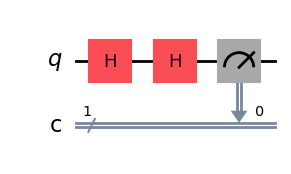

H -> H counts: {'0': 1000}


In [14]:
recoverable = QuantumCircuit(1, 1)
recoverable.h(0)
recoverable.h(0)
recoverable.measure(0, 0)

display(recoverable.draw("mpl"))
recoverable_counts = run_circuit(recoverable, shots=1000)
print("H -> H counts:", recoverable_counts)
plot_histogram(recoverable_counts)
plt.show()

## Bronze B — Insert measurement
After the first `H`, measure the qubit before applying the second `H`. The first measurement produces a definite classical outcome, so the later `H` is no longer simply reversing the same coherent superposition.

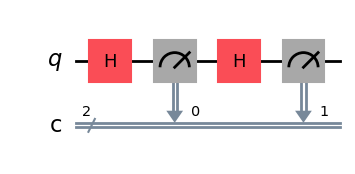

H -> measure -> H -> measure counts: {'11': 949, '00': 974, '10': 1076, '01': 1001}


In [15]:
destroyed = QuantumCircuit(1, 2)
destroyed.h(0)
destroyed.measure(0, 0)
destroyed.h(0)
destroyed.measure(0, 1)

display(destroyed.draw("mpl"))
destroyed_counts = run_circuit(destroyed, shots=4000)
print("H -> measure -> H -> measure counts:", destroyed_counts)
plot_histogram(destroyed_counts)
plt.show()

## Silver A — `X → H → H`
**Prediction:** since `H² = I`, the two H gates cancel, leaving `X`. Starting from `|0⟩`, the final result should be `1`.

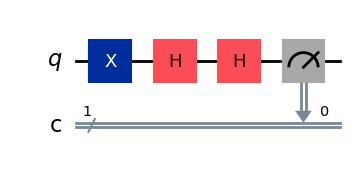

X -> H -> H counts: {'1': 1000}


In [16]:
xhh = QuantumCircuit(1, 1)
xhh.x(0)
xhh.h(0)
xhh.h(0)
xhh.measure(0, 0)

display(xhh.draw("mpl"))
xhh_counts = run_circuit(xhh, shots=1000)
print("X -> H -> H counts:", xhh_counts)
plot_histogram(xhh_counts)
plt.show()

## Silver B — `H → X → H`
**Prediction:** `H X H = Z`, and `Z|0⟩ = |0⟩`, so the final measurement should be `0`.

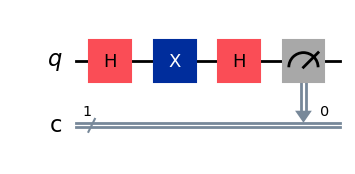

H -> X -> H counts: {'0': 1000}


In [17]:
hxh = QuantumCircuit(1, 1)
hxh.h(0)
hxh.x(0)
hxh.h(0)
hxh.measure(0, 0)

display(hxh.draw("mpl"))
hxh_counts = run_circuit(hxh, shots=1000)
print("H -> X -> H counts:", hxh_counts)
plot_histogram(hxh_counts)
plt.show()

## Gold Preparation / Judge Prediction Practice
The live Gold-style task may involve a judge giving a new H/X sequence and asking you to predict it before running it. The helper below is only for practice and verification.

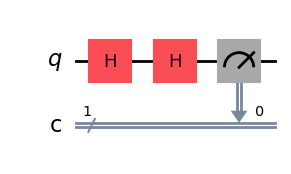

Sequence: H -> H
Counts: {'0': 1000}



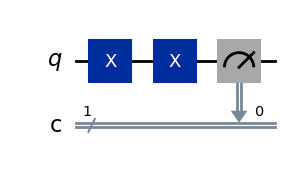

Sequence: X -> X
Counts: {'0': 1000}



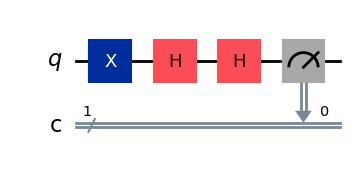

Sequence: X -> H -> H
Counts: {'1': 1000}



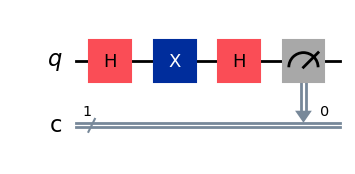

Sequence: H -> X -> H
Counts: {'0': 1000}



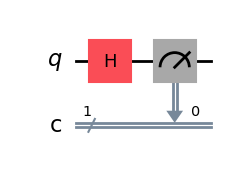

Sequence: H
Counts: {'0': 507, '1': 493}



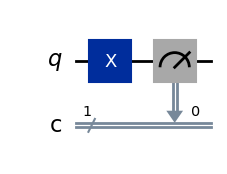

Sequence: X
Counts: {'1': 1000}


In [18]:
def test_sequence(sequence, shots=1000):
    qc = QuantumCircuit(1, 1)
    for gate in sequence:
        gate = gate.upper()
        if gate == "H":
            qc.h(0)
        elif gate == "X":
            qc.x(0)
        else:
            raise ValueError("Only H and X are allowed.")
    qc.measure(0, 0)
    counts = run_circuit(qc, shots=shots)
    display(qc.draw("mpl"))
    print("Sequence:", " -> ".join(sequence))
    print("Counts:", counts)
    return counts

practice_sequences = [
    ["H", "H"],
    ["X", "X"],
    ["X", "H", "H"],
    ["H", "X", "H"],
    ["H"],
    ["X"],
]

for seq in practice_sequences:
    print("\n" + "=" * 50)
    test_sequence(seq)

### Module 04 Interpretation
- `H → H` is reversible and returns the initial state.
- Inserting measurement changes the situation because measurement produces a classical outcome and removes the coherence needed to undo the earlier evolution.
- `X → H → H` gives `1`.
- `H → X → H` gives `0`.

This does **not** prove that any suspect is innocent or guilty. It only establishes the relevant quantum behaviour.

**What this proves:** H and X evolution can be reversible, while measurement produces a classical outcome and removes the coherence needed to reverse the previous evolution.

# Evidence Board
The investigation keeps direct observations separate from statements and interpretations.

In [19]:
evidence_board = {
    "FACT": [
        "Module 01: X prepared a deterministic 1.",
        "Module 01: H produced an approximately 50/50 result.",
        "Module 03: the Bell pair produced same-result 00/11 correlations in the computational basis.",
        "Module 03: the simple pre-agreed shared-bit model also produced only 00/11 in the same basis.",
        "Module 03: changed-basis testing produced different behaviour for the Bell pair and the simple classical model.",
        "Module 05: the damaged stream decoded to ECHO.",
        "Module 04: H followed by H returned the initial state.",
        "Module 04: inserting measurement changed the later behaviour."
    ],
    "CLAIM": [
        'Zara claimed ECHO could use entanglement to send a message faster than light.',
        'Prof. Imran Vance said: "ECHO was never real."',
        'Sana Rao said: "I only deleted a corrupted log."',
        'Bilal Noor said: "I warned her. Nobody listened."',
        'ARIA said: "No unauthorised command was issued."'
    ],
    "INFERENCE": [
        "Same-basis detector agreement alone is insufficient evidence for the stronger communication claim.",
        "Some apparent changes after observation may be explained by measurement effects rather than automatically implying hacking.",
        "The current experiments undermine the claim that correlation alone establishes a usable communication channel."
    ],
    "OPEN QUESTION": [
        "Who configured ARIA's final experiment schedule?",
        "What exactly was in Bilal Noor's missing report?",
        "Why was Sana's log deleted, and what did it contain?",
        "Was ECHO deliberately manipulated?",
        "What happened to Dr. Zara Mahmud?"
    ]
}

for category, entries in evidence_board.items():
    print("\n" + category)
    print("-" * len(category))
    for item in entries:
        print("*", item)


FACT
----
* Module 01: X prepared a deterministic 1.
* Module 01: H produced an approximately 50/50 result.
* Module 03: the Bell pair produced same-result 00/11 correlations in the computational basis.
* Module 03: the simple pre-agreed shared-bit model also produced only 00/11 in the same basis.
* Module 03: changed-basis testing produced different behaviour for the Bell pair and the simple classical model.
* Module 05: the damaged stream decoded to ECHO.
* Module 04: H followed by H returned the initial state.
* Module 04: inserting measurement changed the later behaviour.

CLAIM
-----
* Zara claimed ECHO could use entanglement to send a message faster than light.
* Prof. Imran Vance said: "ECHO was never real."
* Sana Rao said: "I only deleted a corrupted log."
* Bilal Noor said: "I warned her. Nobody listened."
* ARIA said: "No unauthorised command was issued."

INFERENCE
---------
* Same-basis detector agreement alone is insufficient evidence for the stronger communication claim

# Final Interpretation

## What the experiments establish
1. Basic quantum gates behave as expected in the simulator.
2. A Bell pair can produce same-result correlation.
3. A simple pre-agreed shared bit can imitate the same `00/11` statistics in one basis.
4. A changed measurement basis distinguishes the Bell pair from that specific simple classical model.
5. The damaged repetition-coded message decodes to `ECHO`.
6. Measurement behaves differently from reversible unitary gates.

## What the experiments do NOT establish
They do not establish who configured the final ECHO experiment, whether any suspect deliberately manipulated the system, what Bilal's missing report contained, why Sana deleted the log, or what happened to Zara.

## Physics Verdict
**High confidence:** Same-basis detector agreement alone does not demonstrate faster-than-light communication.

## Human Verdict
**Lower confidence:** The available evidence does not establish whether Zara made an honest interpretive mistake or whether another person deliberately influenced or manipulated the experiment.

# Proposed Next Experiment
Use the official teleportation circuit from the released hint notebook and compare:

1. teleportation **with** the required classical correction information,
2. teleportation **without** the classical correction information.

If reliable state recovery requires the classical corrections, that directly tests whether useful information can cross using entanglement alone.

This is proposed as a next experiment and is not part of the selected stretch submission.

# AI / External Assistance
AI tools were used for code scaffolding, debugging, Qiskit syntax support, conceptual explanation, project organization, and documentation.

All experimental outputs shown in this notebook are generated by executing the included code. AI-generated suggestions are not treated as experimental evidence.